# Лабораторная работа № 12. Деревья решений и случайный лес

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Применить деревья решений и случайный лес для определения сорта стекла, исследовать влияние глубины, подобрать гиперпараметры (GridSearchCV) и оформить итоговый программный продукт — бота для определения сорта стекла.

## 1. Теоретическая часть

**1. Дерево решений** — модель в виде дерева правил «если признак ≤ порог, то влево, иначе вправо»; листья содержат прогноз класса. Строится жадно сверху вниз: в каждом узле выбирается признак и порог, дающие наилучшее разбиение, и процесс повторяется рекурсивно, пока не выполнится критерий остановки.

**2. Критерии качества разбиения:** индекс Джини G = 1 − Σpₖ² и энтропия H = −Σpₖ log pₖ (для регрессии — дисперсия/MSE). Выбирается разбиение с наибольшим уменьшением неопределённости (прироста информации).

**3. Переобучение.** Неограниченное дерево может разделить обучающую выборку до единичных объектов и запомнить шум: на обучении точность 100 %, на тесте — заметно ниже. Деревья склонны к этому из-за высокой гибкости и неустойчивости (небольшое изменение данных меняет структуру). Борьба: ограничение max_depth, min_samples_split/leaf, обрезка (pruning).

**4. Случайный лес** — ансамбль многих деревьев, каждое из которых обучается на бутстреп-выборке и использует случайное подмножество признаков в каждом узле; ответы усредняются (голосуют). Он уменьшает дисперсию и переобучение одиночных деревьев.

**5. Почему ансамбли устойчивее?** Ошибки разных деревьев частично независимы и взаимно компенсируются при усреднении (снижение дисперсии без роста смещения), поэтому результат менее чувствителен к шуму и выбросам, чем у одиночной модели.

## 2. Практическая часть

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

# ---------- сквозной пайплайн подготовки данных (ЛР 5-7) ----------
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def clean_glass(d):
    """ЛР 5: пропуски, допустимые пределы, дубликаты."""
    d = d.copy()
    d = d.dropna()
    ok = d[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1)
    ok &= d["RI"].between(1.3, 1.7)
    return d[ok].drop_duplicates().reset_index(drop=True)

def scale_glass(d):
    """ЛР 6: стандартизация признаков (целевая Type не масштабируется)."""
    s = d.copy()
    s[FEATURES] = StandardScaler().fit_transform(d[FEATURES])
    return s

def select_glass(s):
    """ЛР 7: три метода отбора (фильтр, обёртка, встроенный) + голосование >= 2."""
    X, y = s[FEATURES], s["Type"]
    f1 = set(X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()])
    f2 = set(X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()])
    f3 = set(X.columns[SelectFromModel(RandomForestClassifier(n_estimators=300, random_state=42), threshold="median").fit(X, y).get_support()])
    votes = {f: (f in f1) + (f in f2) + (f in f3) for f in FEATURES}
    keep = [f for f in FEATURES if votes[f] >= 2]
    return s[keep + ["Type"]], keep

clean  = clean_glass(df)
scaled = scale_glass(clean)
selected, SEL = select_glass(scaled)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             r2_score, mean_absolute_error, mean_squared_error)
X, y = selected[SEL], selected["Type"]
CLASSES = np.array(sorted(y.unique()))
def split(rs=42):
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=rs)
X_train, X_test, y_train, y_test = split(42)
print("Входная выборка (после отбора признаков):", selected.shape, "| признаки:", SEL)
print("train:", X_train.shape, "| test:", X_test.shape)
print("Классы в train:", y_train.value_counts().sort_index().to_dict(), "| в test:", y_test.value_counts().sort_index().to_dict())
def report(model, name, Xte=None, yte=None):
    Xte = X_test if Xte is None else Xte; yte = y_test if yte is None else yte
    p = model.predict(Xte)
    return {"модель": name, "accuracy": accuracy_score(yte, p), "F1 macro": f1_score(yte, p, average="macro"),
            "F1 weighted": f1_score(yte, p, average="weighted")}

Входная выборка (после отбора признаков): (213, 7) | признаки: ['Na', 'Mg', 'Al', 'K', 'Ca', 'Ba']
train: (170, 6) | test: (43, 6)
Классы в train: {1: 55, 2: 61, 3: 14, 5: 10, 6: 7, 7: 23} | в test: {1: 14, 2: 15, 3: 3, 5: 3, 6: 2, 7: 6}


### 2.1. Базовый уровень

In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf = RandomForestClassifier(random_state=42).fit(X_train, y_train)
for n, m in [("DecisionTree (по умолчанию)", dt), ("RandomForest (по умолчанию)", rf)]:
    p = m.predict(X_test)
    print(f"{n}: accuracy = {accuracy_score(y_test, p):.3f}, F1 macro = {f1_score(y_test, p, average='macro'):.3f}")
print("\nПервые вероятности леса:"); display(pd.DataFrame(rf.predict_proba(X_test)[:3], columns=rf.classes_).round(2))
print(classification_report(y_test, rf.predict(X_test), target_names=[TYPE_NAMES[k] for k in CLASSES], zero_division=0))

DecisionTree (по умолчанию): accuracy = 0.651, F1 macro = 0.644
RandomForest (по умолчанию): accuracy = 0.721, F1 macro = 0.640

Первые вероятности леса:


,1,2,3,5,6,7
0,0.00,0.02,0.00,0.0,0.10,0.88
1,0.02,0.11,0.04,0.8,0.02,0.01
2,0.11,0.80,0.09,0.0,0.00,0.00


                         precision    recall  f1-score   support

    окна зданий (float)       0.69      0.79      0.73        14
окна зданий (non-float)       0.77      0.67      0.71        15
      окна авто (float)       0.00      0.00      0.00         3
             контейнеры       0.67      0.67      0.67         3
                 посуда       0.67      1.00      0.80         2
                   фары       0.86      1.00      0.92         6

               accuracy                           0.72        43
              macro avg       0.61      0.69      0.64        43
           weighted avg       0.69      0.72      0.70        43



### 2.2. Влияние глубины дерева

,глубина факт.,листьев,train acc,test acc
max_depth,,,,
1,1,2,0.471,0.488
2,2,4,0.629,0.605
3,3,7,0.724,0.674
4,4,11,0.776,0.698
5,5,16,0.806,0.674
6,6,21,0.835,0.581
8,8,30,0.912,0.651
10,10,33,0.924,0.651
None,17,51,1.000,0.651


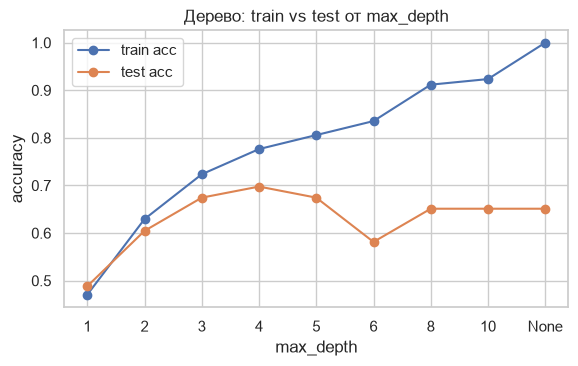

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({"max_depth": "None" if d is None else d, "глубина факт.": m.get_depth(), "листьев": m.get_n_leaves(), "train acc": m.score(X_train, y_train), "test acc": m.score(X_test, y_test)})
dd = pd.DataFrame(rows).set_index("max_depth"); display(dd.round(3))
dd[["train acc", "test acc"]].plot(marker="o", figsize=(6.5, 3.6), title="Дерево: train vs test от max_depth"); plt.ylabel("accuracy"); plt.show()

**Ответ.** С ростом глубины точность на обучении растёт до 1.0 (при глубине 17), а на тесте достигает максимума 0.70 при глубине 4 и дальше колеблется на уровне 0.58–0.67 — классический признак переобучения; умеренная глубина (3–5) даёт лучший компромисс.

In [4]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=42)
models = {"DecisionTree (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=42), "DecisionTree (без ограничений)": DecisionTreeClassifier(random_state=42),
          "RandomForest": RandomForestClassifier(random_state=42), "kNN (k=5)": KNeighborsClassifier(5), "LogisticRegression": LogisticRegression(max_iter=3000)}
rows = []
for n, m in models.items():
    m.fit(X_train, y_train); r = report(m, n); r["CV accuracy"] = cross_val_score(m, X, y, cv=cv).mean(); rows.append(r)
cmp = pd.DataFrame(rows).set_index("модель"); display(cmp.round(3))

,accuracy,F1 macro,F1 weighted,CV accuracy
модель,,,,
DecisionTree (depth=4),0.698,0.604,0.679,0.657
DecisionTree (без ограничений),0.651,0.644,0.646,0.643
RandomForest,0.721,0.640,0.700,0.742
kNN (k=5),0.698,0.632,0.675,0.671
LogisticRegression,0.581,0.567,0.558,0.620


### 2.3. Структура моделей, random_state, GridSearchCV

Дерево по умолчанию: глубина = 17, листьев = 51, узлов = 101


,важность
Mg,0.231
Al,0.209
Ba,0.174
Na,0.159
Ca,0.155
K,0.071


Используются в разбиениях: ['Mg', 'Al', 'Ba', 'Na', 'Ca', 'K']


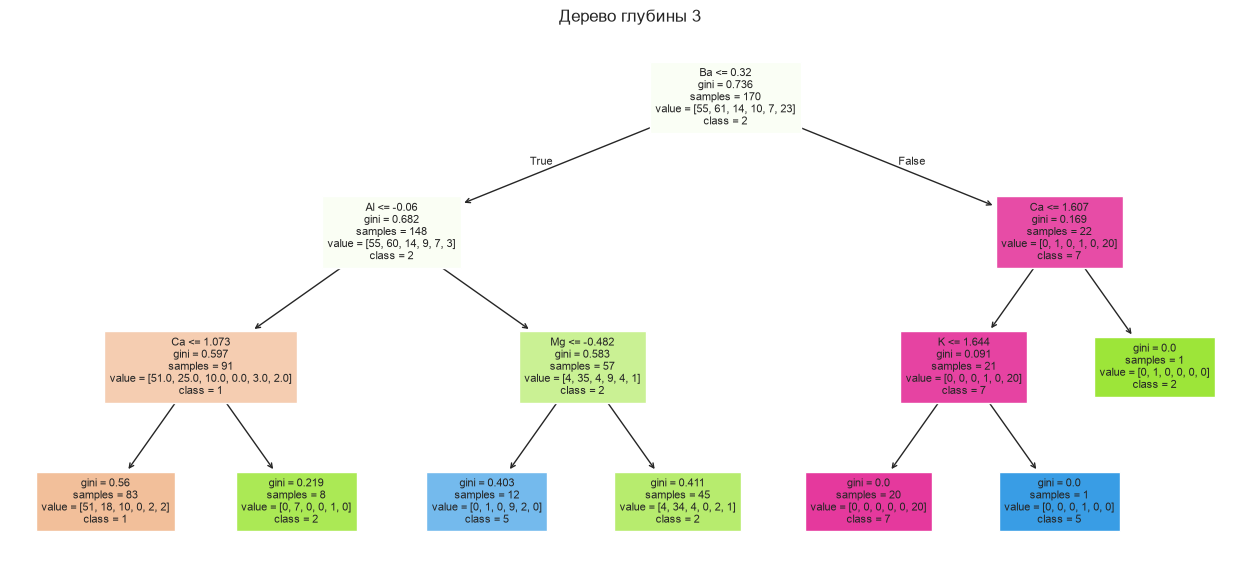

|--- Ba <= 0.32
|   |--- Al <= -0.06
|   |   |--- Ca <= 1.07
|   |   |   |--- class: 1
|   |   |--- Ca >  1.07
|   |   |   |--- class: 2
|   |--- Al >  -0.06
|   |   |--- Mg <= -0.48
|   |   |   |--- class: 5
|   |   |--- Mg >  -0.48
|   |   |   |--- class: 2
|--- Ba >  0.32
|   |--- Ca <= 1.61
|   |   |--- K <= 1.64
|   |   |   |--- class: 7
|   |   |--- K >  1.64
|   |   |   |--- class: 5
|   |--- Ca >  1.61
|   |   |--- class: 2

Случайный лес: деревьев = 100, глубина (средняя/макс) = 11.9/19, листьев в среднем = 40.3


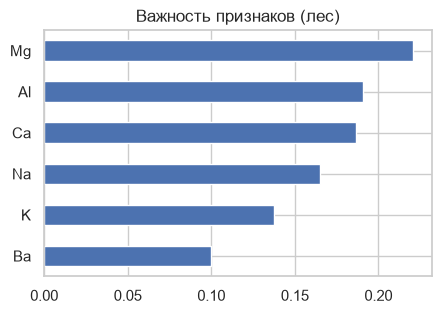

Вывод: одно дерево проще (меньше узлов), лес в десятки раз сложнее по числу правил, но стабильнее.


In [5]:
print(f"Дерево по умолчанию: глубина = {dt.get_depth()}, листьев = {dt.get_n_leaves()}, узлов = {dt.tree_.node_count}")
used = pd.Series(dt.feature_importances_, index=SEL).sort_values(ascending=False)
display(used.round(3).to_frame("важность"))
print("Используются в разбиениях:", [f for f, v in used.items() if v > 0])
dt3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(16, 7)); plot_tree(dt3, feature_names=SEL, class_names=[str(k) for k in dt3.classes_], filled=True, fontsize=8); plt.title("Дерево глубины 3"); plt.show()
print(export_text(dt3, feature_names=SEL, max_depth=3))
depths = [e.get_depth() for e in rf.estimators_]; leaves = [e.get_n_leaves() for e in rf.estimators_]
print(f"Случайный лес: деревьев = {len(rf.estimators_)}, глубина (средняя/макс) = {np.mean(depths):.1f}/{max(depths)}, листьев в среднем = {np.mean(leaves):.1f}")
pd.Series(rf.feature_importances_, index=SEL).sort_values().plot.barh(figsize=(5, 3.2), title="Важность признаков (лес)"); plt.show()
print("Вывод: одно дерево проще (меньше узлов), лес в десятки раз сложнее по числу правил, но стабильнее.")

In [6]:
rows = []
for rs in [0, 1, 7, 42, 123]:
    rf_ = RandomForestClassifier(random_state=rs).fit(X_train, y_train)
    Xtr, Xte, ytr, yte = split(rs); rf2 = RandomForestClassifier(random_state=rs).fit(Xtr, ytr)
    rows.append({"random_state": rs, "лес (фикс. разбиение) acc": rf_.score(X_test, y_test), "лес + новое разбиение acc": rf2.score(Xte, yte)})
rs_t = pd.DataFrame(rows).set_index("random_state"); display(rs_t.round(3)); print("std:", rs_t.std().round(3).to_dict())

,лес (фикс. разбиение) acc,лес + новое разбиение acc
random_state,,
0,0.698,0.721
1,0.674,0.744
7,0.698,0.698
42,0.721,0.721
123,0.674,0.767


std: {'лес (фикс. разбиение) acc': 0.019, 'лес + новое разбиение acc': 0.027}


In [7]:
from sklearn.model_selection import GridSearchCV
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42),
                       {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4], "criterion": ["gini", "entropy"]},
                       cv=5, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
print("DecisionTree — лучшие параметры:", grid_dt.best_params_)
print(f"  CV accuracy = {grid_dt.best_score_:.3f} | test accuracy = {grid_dt.score(X_test, y_test):.3f} (до подбора: {dt.score(X_test, y_test):.3f})")

DecisionTree — лучшие параметры: {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 4, 'min_samples_split': 2}
  CV accuracy = 0.653 | test accuracy = 0.651 (до подбора: 0.651)


RandomForest — лучшие параметры: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
  CV accuracy = 0.729 | test accuracy = 0.698 (до подбора: 0.721)


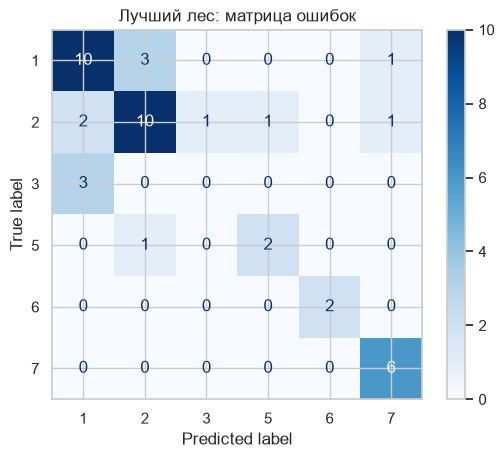

In [8]:
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42),
                       {"n_estimators": [100, 300], "max_depth": [None, 5, 10], "min_samples_split": [2, 5], "min_samples_leaf": [1, 2]},
                       cv=5, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
print("RandomForest — лучшие параметры:", grid_rf.best_params_)
print(f"  CV accuracy = {grid_rf.best_score_:.3f} | test accuracy = {grid_rf.score(X_test, y_test):.3f} (до подбора: {rf.score(X_test, y_test):.3f})")
best_rf = grid_rf.best_estimator_
ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test, display_labels=best_rf.classes_, cmap="Blues"); plt.title("Лучший лес: матрица ошибок"); plt.show()

### Итоговый текст по ЛР 12

Деревья решений и случайный лес — основные классические модели для табличных данных в курсе прикладного ИИ: они не требуют масштабирования, работают с нелинейными зависимостями и взаимодействиями признаков, давая высокое качество «из коробки». По интерпретируемости одиночное дерево превосходит все остальные модели курса: его можно нарисовать и прочитать как набор правил по оксидам, тогда как лес из сотен деревьев интерпретируется лишь через важности признаков. По устойчивости лес заметно лучше: дерево сильно меняется при смене выборки и склонно к переобучению (100 % на обучении при заметно меньшей точности на тесте), а усреднение деревьев лесом сглаживает этот эффект, и результат слабее зависит от random_state. По вычислительной сложности дерево обучается и предсказывает очень быстро, лес стоит в десятки раз дороже по числу узлов и времени (в среднем ≈ 40 листьев на дерево при 100 деревьях против 51 листа у одного дерева — то есть ≈ 4000 правил), а подбор гиперпараметров GridSearchCV умножает затраты на размер сетки и число фолдов. Подбор параметров дал дереву лишь небольшой выигрыш в кросс-валидации (0.643 → 0.653; лучшие параметры: max_depth = 6, min_samples_leaf = 4), на тесте результат не изменился (0.651), а лес оказался нечувствителен к параметрам: лучшая в сетке конфигурация (300 деревьев) почти совпадает с настройками по умолчанию, CV 0.729, на тесте 0.698 против 0.721 у «дефолтного» леса — разница в один объект из 43 лежит в пределах шума. Дерево предпочтительно, когда нужны прозрачные правила и объяснимость (например, для экспертов-стекловаров), лес — когда важнее точность и устойчивость, а время и память не критичны. На данных о стекле лес даёт наивысшую среднюю точность среди всех моделей курса (CV accuracy ≈ 0.73–0.74 против 0.67 у kNN, 0.66 у дерева, 0.62 у логистической регрессии и 0.45 у наивного Байеса), что объясняется нелинейным характером различий между сортами по сочетанию оксидов. На основе этого результата лучший лес выбран ядром итогового бота для определения сорта стекла (см. ниже).

---
## 3. Итоговый программный продукт: бот для определения сорта стекла

На основе всего пайплайна (очистка → масштабирование → отбор признаков → случайный лес с подобранными параметрами) собирается единая модель `Pipeline`, принимающая **сырые** значения оксидов (в %) и показатель преломления и возвращающая сорт стекла с вероятностями. Затем она оборачивается в бота.

In [9]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
raw = clean_glass(df)                                   # очищенные данные, без масштабирования
Xr, yr = raw[SEL], raw["Type"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=42)
final = Pipeline([("scaler", StandardScaler()), ("model", RandomForestClassifier(**grid_rf.best_params_, random_state=42))]).fit(Xr_tr, yr_tr)
pf = final.predict(Xr_te)
print(f"Итоговая модель (scaler внутри Pipeline, без утечки): accuracy = {accuracy_score(yr_te, pf):.3f}, F1 macro = {f1_score(yr_te, pf, average='macro'):.3f}")
final.fit(Xr, yr)                                       # итоговое обучение на всех данных
joblib.dump({"pipeline": final, "features": SEL, "type_names": TYPE_NAMES}, "glass_model.joblib")
print("Модель сохранена в glass_model.joblib; признаки на входе:", SEL)

Итоговая модель (scaler внутри Pipeline, без утечки): accuracy = 0.721, F1 macro = 0.662


Модель сохранена в glass_model.joblib; признаки на входе: ['Na', 'Mg', 'Al', 'K', 'Ca', 'Ba']


In [10]:
%%writefile glass_bot.py
"""Бот для определения сорта стекла по химическому составу (датасет Glass Identification, UCI / Kaggle uciml/glass).
Запуск Telegram-бота:  pip install python-telegram-bot joblib scikit-learn pandas
                       export BOT_TOKEN=<токен от @BotFather>;  python glass_bot.py
Проверка без Telegram: python glass_bot.py --console
"""
import os, re, sys
import joblib
import pandas as pd

BUNDLE = joblib.load(os.path.join(os.path.dirname(os.path.abspath(__file__)), "glass_model.joblib"))
PIPE, FEATURES, NAMES = BUNDLE["pipeline"], BUNDLE["features"], BUNDLE["type_names"]
HELP = ("Пришлите состав стекла в процентах, например:\n"
        "Na=13.4 Mg=3.5 Al=1.2 K=0.5 Ca=8.7 Ba=0\n"
        f"Нужные признаки: {', '.join(FEATURES)}. Пример можно получить командой /example")
EXAMPLE = "Na=14.4 Mg=0.5 Al=2.1 K=0.3 Ca=8.5 Ba=1.0"


def parse(text):
    vals = {k.capitalize(): float(v.replace(",", ".")) for k, v in re.findall(r"([A-Za-z]{1,2})\s*[=:]\s*(-?\d+(?:[.,]\d+)?)", text)}
    missing = [f for f in FEATURES if f not in vals]
    if missing:
        raise ValueError("Не хватает значений: " + ", ".join(missing))
    if any(not 0 <= vals[f] <= 100 for f in FEATURES):
        raise ValueError("Содержание оксидов должно быть в пределах 0-100 %")
    return pd.DataFrame([[vals[f] for f in FEATURES]], columns=FEATURES)


def answer(text):
    """Возвращает текст ответа бота на сообщение пользователя."""
    try:
        x = parse(text)
    except ValueError as e:
        return f"⚠️ {e}\n\n{HELP}"
    proba = PIPE.predict_proba(x)[0]
    order = proba.argsort()[::-1][:3]
    classes = PIPE.classes_
    lines = [f"🔎 Наиболее вероятный сорт: {NAMES[classes[order[0]]]} (тип {classes[order[0]]}), уверенность {proba[order[0]]:.0%}", "Другие варианты:"]
    lines += [f"  • {NAMES[classes[i]]}: {proba[i]:.0%}" for i in order[1:]]
    if proba[order[0]] < 0.5:
        lines.append("⚠️ Уверенность низкая — результат следует перепроверить лабораторно.")
    return "\n".join(lines)


def main():
    from telegram import Update
    from telegram.ext import Application, CommandHandler, MessageHandler, ContextTypes, filters

    async def start(update: Update, ctx: ContextTypes.DEFAULT_TYPE):
        await update.message.reply_text("Привет! Я определяю сорт стекла по химическому составу.\n" + HELP)

    async def example(update: Update, ctx: ContextTypes.DEFAULT_TYPE):
        await update.message.reply_text(EXAMPLE + "\n\n" + answer(EXAMPLE))

    async def on_text(update: Update, ctx: ContextTypes.DEFAULT_TYPE):
        await update.message.reply_text(answer(update.message.text))

    app = Application.builder().token(os.environ["BOT_TOKEN"]).build()
    app.add_handler(CommandHandler(["start", "help"], start))
    app.add_handler(CommandHandler("example", example))
    app.add_handler(MessageHandler(filters.TEXT & ~filters.COMMAND, on_text))
    app.run_polling()


if __name__ == "__main__":
    if "--console" in sys.argv:
        print(HELP)
        while True:
            try:
                print(answer(input("> ")))
            except (EOFError, KeyboardInterrupt):
                break
    else:
        main()

Overwriting glass_bot.py


### Проверка работы бота (имитация диалога)

In [11]:
import importlib, sys
sys.path.insert(0, ".")
import glass_bot; importlib.reload(glass_bot)
dialog = ["Na=13.64 Mg=4.49 Al=1.10 K=0.06 Ca=8.75 Ba=0",        # образец №1 из набора (сорт 1)
          "Na=14.4 Mg=0.5 Al=2.1 K=0.3 Ca=8.5 Ba=1.0",           # типичные фары (сорт 7)
          "Na=12.8 Mg=0.7 Al=2.0 K=1.5 Ca=10.1 Ba=0.2",          # типичные контейнеры (сорт 5)
          "Na=13.4 Mg=3.5",                                       # неполный ввод
          "привет"]
for msg in dialog:
    print("👤", msg); print("🤖", glass_bot.answer(msg), "\n")

👤

 Na=13.64 Mg=4.49 Al=1.10 K=0.06 Ca=8.75 Ba=0
🤖 🔎 Наиболее вероятный сорт: окна зданий (float) (тип 1), уверенность 73%
Другие варианты:
  • окна зданий (non-float): 15%
  • окна авто (float): 11% 

👤 Na=14.4 Mg=0.5 Al=2.1 K=0.3 Ca=8.5 Ba=1.0
🤖 🔎 Наиболее вероятный сорт: фары (тип 7), уверенность 95%
Другие варианты:
  • окна зданий (non-float): 3%
  • посуда: 1% 

👤 Na=12.8 Mg=0.7 Al=2.0 K=1.5 Ca=10.1 Ba=0.2
🤖 🔎 Наиболее вероятный сорт: контейнеры (тип 5), уверенность 76%
Другие варианты:
  • окна зданий (non-float): 18%
  • фары: 4% 

👤 Na=13.4 Mg=3.5
🤖 ⚠️ Не хватает значений: Al, K, Ca, Ba

Пришлите состав стекла в процентах, например:
Na=13.4 Mg=3.5 Al=1.2 K=0.5 Ca=8.7 Ba=0
Нужные признаки: Na, Mg, Al, K, Ca, Ba. Пример можно получить командой /example 

👤 привет
🤖 ⚠️ Не хватает значений: Na, Mg, Al, K, Ca, Ba

Пришлите состав стекла в процентах, например:
Na=13.4 Mg=3.5 Al=1.2 K=0.5 Ca=8.7 Ba=0
Нужные признаки: Na, Mg, Al, K, Ca, Ba. Пример можно получить командой /example 



In [12]:
# контроль разбора ввода на реальных образцах из таблицы (модель обучена на всех данных, поэтому это проверка работы бота, а не оценка качества)
smp = raw.groupby("Type").head(1)
for _, r in smp.iterrows():
    msg = " ".join(f"{f}={r[f]}" for f in SEL)
    top = glass_bot.answer(msg).splitlines()[0]
    print(f"истина: тип {int(r['Type'])} | {top}")

истина: тип 1 | 🔎 Наиболее вероятный сорт: окна зданий (float) (тип 1), уверенность 73%
истина: тип 2 | 🔎 Наиболее вероятный сорт: окна зданий (non-float) (тип 2), уверенность 72%
истина: тип 3 | 🔎 Наиболее вероятный сорт: окна авто (float) (тип 3), уверенность 69%
истина: тип 5 | 🔎 Наиболее вероятный сорт: контейнеры (тип 5), уверенность 65%


истина: тип 6 | 🔎 Наиболее вероятный сорт: посуда (тип 6), уверенность 84%
истина: тип 7 | 🔎 Наиболее вероятный сорт: фары (тип 7), уверенность 72%


## Общий вывод по продукту
Разработан и проверен программный продукт «бот для определения сорта стекла»: файл `glass_model.joblib` содержит обученный `Pipeline` (масштабирование + случайный лес с подобранными параметрами), а `glass_bot.py` реализует разбор сообщения, валидацию ввода, предсказание с вероятностями трёх наиболее вероятных сортов и предупреждение при низкой уверенности. Бот запускается как Telegram-бот (нужен токен от @BotFather) или в консольном режиме `python glass_bot.py --console`. Ограничения: модель обучена на 213 образцах, малые классы (посуда, контейнеры, окна авто) распознаются хуже, поэтому ответ носит вспомогательный характер.